# Resolution Filter

Plotting HeatFlux_kyst vs ky can be an identifier for resolution quality of the simulation. 

In [1]:
import pugs

import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt

import netCDF4 as nc

import os
from glob import glob
from pathlib import Path

In [2]:
folder = "/Users/zacharygottlieb/local/stellarator/data/20241119-01-008_200_configs"
file = "000089_theta0_3.14_zeta0_0.00/gx.out.nc"

file_path = os.path.join(folder, file)
print(file_path)

/Users/zacharygottlieb/local/stellarator/data/20241119-01-008_200_configs/000089_theta0_3.14_zeta0_0.00/gx.out.nc


In [3]:
# Retrieve HeatFlux_kyst and ky from the netCDF file
ds = nc.Dataset(file_path, "r")
HeatFlux_kyst = ds["Diagnostics"]["HeatFlux_kyst"][:]
ky = ds["Grids"]["ky"][:]

In [4]:
# Identify steady-state start time and index
_df = pugs.load_file(file_path, "HeatFlux_st")
start_time = pugs.steady_state(_df, "HeatFlux_st", method="linreg")
start_idx = np.where(_df["time"] >= start_time)[0][0]
print(f"steady-state start time: {start_time:.5g}")

steady-state start time: 35.719


In [5]:
# Refactor data into DataFrame of format ky vs HeatFlux_kyst (for each time step)
data = {"ky": ky}
for i in range(len(HeatFlux_kyst)):
    data[f"HeatFlux_kyst_{i}"] = HeatFlux_kyst[i].flatten()
df = pd.DataFrame(data)

# Calculate mean HeatFlux_kyst for each ky value after the steady-state start index
means = []
for i in range(len(df)):
    means.append(df.loc[i, f"HeatFlux_kyst_{start_idx}":].mean())
df.insert(1, "mean_HeatFlux_kyst", means)

# Identify the ky value corresponding to the maximum of mean HeatFlux_kyst values
peak_mean_ky = ky[np.argmax(df["mean_HeatFlux_kyst"])]
print(f"peak_mean_ky: {peak_mean_ky:.5g}")

peak_mean_ky: 0.7


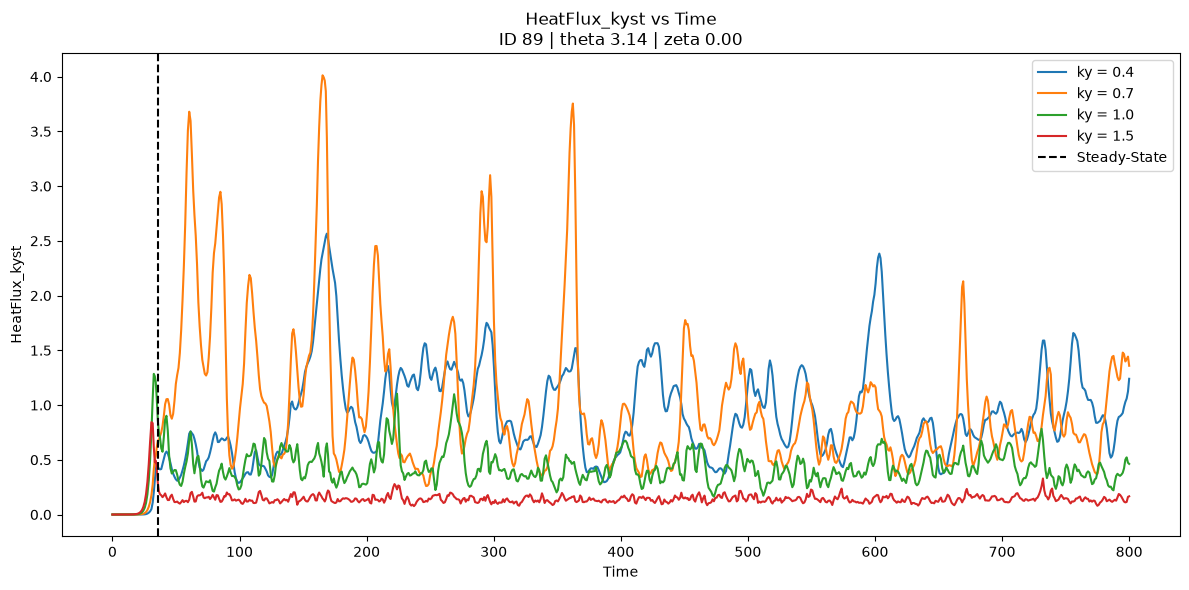

In [6]:
selected_ky = [0.4, 0.7, 1.0, 1.5]

flux_columns = [column for column in df.columns if column.startswith("HeatFlux_kyst_")]
time = _df["time"]

fig, ax = plt.subplots(figsize=(12, 6))

for i in selected_ky:
    row = (df["ky"] - i).abs().idxmin()
    heatflux = df.loc[row, flux_columns].to_numpy()
    ax.plot(time, heatflux, label=f"ky = {df.loc[row, 'ky']:.1f}")

ax.axvline(start_time, color="k", ls="--", label="Steady-State")

ax.set_title("HeatFlux_kyst vs Time\nID 89 | theta 3.14 | zeta 0.00")
ax.set_xlabel("Time")
ax.set_ylabel("HeatFlux_kyst")

ax.legend()
plt.tight_layout()
plt.show()


In [7]:
input_csv = "all_HeatFlux_st_linreg_slope_tol_0.1.csv"
output_csv = "all_HeatFlux_kyst_peak_mean_ky.csv"
start_df = pd.read_csv(input_csv, dtype={"id": str})

def process_folder(folder):
    folders = sorted(glob(os.path.join(folder, "*_theta0_*_zeta0_*")))
    results = []

    for f in folders:
        file = os.path.join(f, "gx.out.nc")
        parts = os.path.basename(f).split("_")
        exp_info = {
            "id": parts[0],
            "theta": parts[2],
            "zeta": parts[4],
            "file": file,
        }

        with nc.Dataset(file, "r") as ds:
            HeatFlux_kyst = ds["Diagnostics"]["HeatFlux_kyst"][:]
            ky = ds["Grids"]["ky"][:]
            time = ds["Grids"]["time"][:]

        # Look up this run's steady-state results.
        run = start_df.loc[start_df["file"] == file].iloc[0]
        start_time = run["start_time"]

        if pd.isna(start_time):
            start_idx = 0  # Use the full run if no steady state was detected.
        else:
            start_idx = np.where(time >= start_time)[0][0]

        # Store one row per ky and one column per time step.
        data = {"ky": ky}
        for i in range(len(HeatFlux_kyst)):
            data[f"HeatFlux_kyst_{i}"] = HeatFlux_kyst[i].flatten()
        df = pd.DataFrame(data)

        # Average each ky row from the steady-state start onward.
        means = []
        for i in range(len(df)):
            means.append(df.loc[i, f"HeatFlux_kyst_{start_idx}":].mean())
        df.insert(1, "mean_HeatFlux_kyst", means)

        # Select the ky with the largest mean heat flux.
        peak_mean_ky = df.loc[df["mean_HeatFlux_kyst"].idxmax(), "ky"]

        results.append({
            **exp_info,
            "ky": peak_mean_ky,
            "start_time": start_time,
            "mean": run["mean"],
            "std": run["std"],
        })

    return pd.DataFrame(results)

In [8]:
all_df = process_folder(folder)
all_df.to_csv(output_csv, index=False)
print(f"Saved {len(all_df)} runs to {output_csv}")


Saved 800 runs to all_HeatFlux_kyst_peak_mean_ky.csv


In [9]:
all_df = pd.read_csv(output_csv, dtype={"id": str})
all_df.head()


,id,theta,zeta,file,ky,start_time,mean,std
0,000000,0.00,0.00,/Users/zacharygottlieb/local/stellarator/data/...,0.4,NaN,NaN,NaN
1,000000,0.00,1.57,/Users/zacharygottlieb/local/stellarator/data/...,1.1,NaN,NaN,NaN
2,000000,3.14,0.00,/Users/zacharygottlieb/local/stellarator/data/...,0.5,13.144094,51.800823,6.691688
3,000000,3.14,1.57,/Users/zacharygottlieb/local/stellarator/data/...,1.9,NaN,NaN,NaN
4,000001,0.00,0.00,/Users/zacharygottlieb/local/stellarator/data/...,1.1,19.631783,55.760700,8.647595


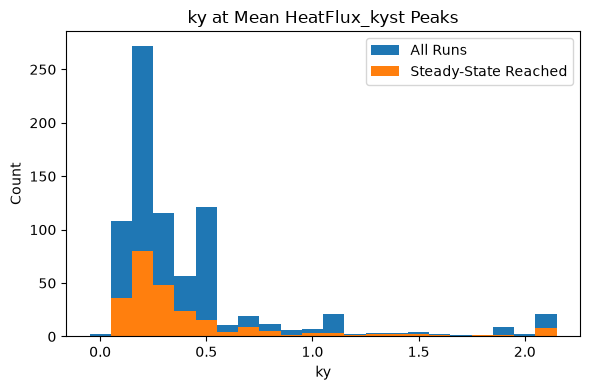

In [10]:
ky_values = np.sort(all_df["ky"].dropna().unique())

if len(ky_values) == 1:
    ky_bins = [ky_values[0] - 0.05, ky_values[0] + 0.05]
else:
    ky_bins = np.r_[
        ky_values[0] - (ky_values[1] - ky_values[0]) / 2,
        (ky_values[:-1] + ky_values[1:]) / 2,
        ky_values[-1] + (ky_values[-1] - ky_values[-2]) / 2,
    ]

fig, ax = plt.subplots(figsize=(6, 4))

ax.hist(all_df["ky"], bins=ky_bins, label="All Runs")
ax.hist(
    all_df.loc[all_df["start_time"].notna(), "ky"],
    bins=ky_bins,
    label="Steady-State Reached",
)

ax.set_title("ky at Mean HeatFlux_kyst Peaks")
ax.set_xlabel("ky")
ax.set_ylabel("Count")
ax.legend()

plt.tight_layout()
plt.show()

In [11]:
# Calculate the IQR in log space.
log_ky = np.log(all_df["ky"].where(all_df["ky"] > 0))

Q1 = log_ky.quantile(0.25)
Q3 = log_ky.quantile(0.75)
IQR = Q3 - Q1

lower_log = Q1 - 1.5 * IQR
upper_log = Q3 + 1.5 * IQR

mask = log_ky.between(lower_log, upper_log)

df = all_df.loc[mask].copy()
failed_df = all_df.loc[~mask].copy()

ss_df = df.loc[df["start_time"].notna()].copy()
ss_failed_df = failed_df.loc[failed_df["start_time"].notna()].copy()

# Convert the cutoffs back to ky units for display.
lower = np.exp(lower_log)
upper = np.exp(upper_log)

print(f"Peak ky interval: [{lower:.3f}, {upper:.3f}]")
print(f"{len(df)} runs pass resolution filter")
print(f"{len(failed_df)} runs fail resolution filter")
print(f"{len(ss_df)} runs pass filter and reach steady state")
print(f"{len(ss_failed_df)} runs fail filter and reach steady state")

Peak ky interval: [0.051, 1.976]
775 runs pass resolution filter
25 runs fail resolution filter
238 runs pass filter and reach steady state
8 runs fail filter and reach steady state


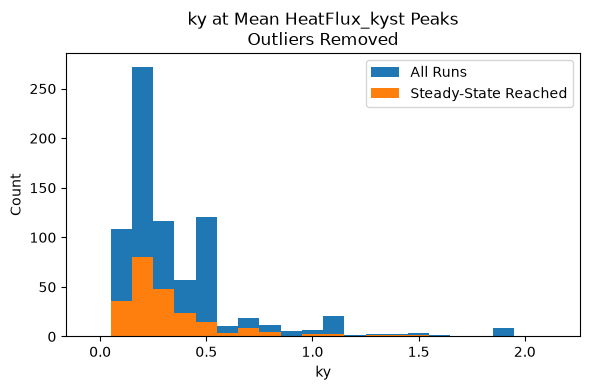

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.hist(df["ky"], bins=ky_bins, label="All Runs")
ax.hist(ss_df["ky"], bins=ky_bins, label="Steady-State Reached")

ax.set_title("ky at Mean HeatFlux_kyst Peaks\nOutliers Removed")
ax.set_xlabel("ky")
ax.set_ylabel("Count")
ax.legend()

plt.tight_layout()
plt.show()

In [13]:
logx = np.log(ss_df["start_time"])
logy = np.log(ss_df["mean"])

slope, intercept, r_val, p_val, std_err = st.linregress(logx, logy)

print(f"Mean HeatFlux_st = {np.exp(intercept):.5f} * (Time to Steady-State)^({slope:.5f})")
print(f"R-squared: {r_val**2:.5f}")


Mean HeatFlux_st = 1823.22426 * (Time to Steady-State)^(-1.36126)
R-squared: 0.52397


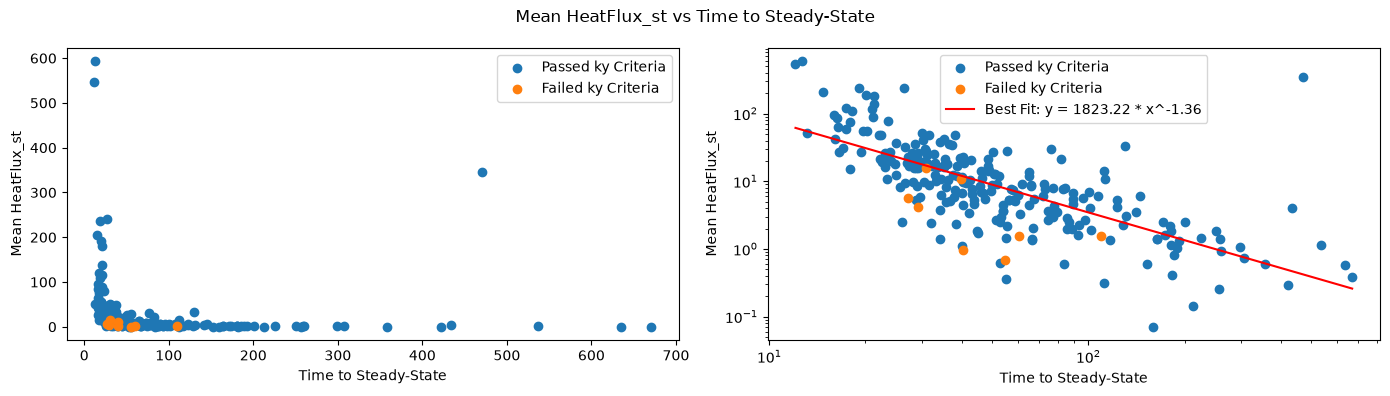

In [14]:
xline = np.linspace(ss_df["start_time"].min(), ss_df["start_time"].max(), 400)
yline = np.exp(intercept) * xline**slope

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for i, ax in enumerate(axes):
    ax.scatter(ss_df["start_time"], ss_df["mean"], label="Passed ky Criteria")
    ax.scatter(ss_failed_df["start_time"], ss_failed_df["mean"], label="Failed ky Criteria")
    ax.set_xlabel("Time to Steady-State")
    ax.set_ylabel("Mean HeatFlux_st")

    if i == 1:
        ax.plot(xline, yline, color="red",
                label=f"Best Fit: y = {np.exp(intercept):.2f} * x^{slope:.2f}")
        ax.set_xscale("log")
        ax.set_yscale("log")

    ax.legend()

fig.suptitle("Mean HeatFlux_st vs Time to Steady-State")
plt.tight_layout()
plt.show()


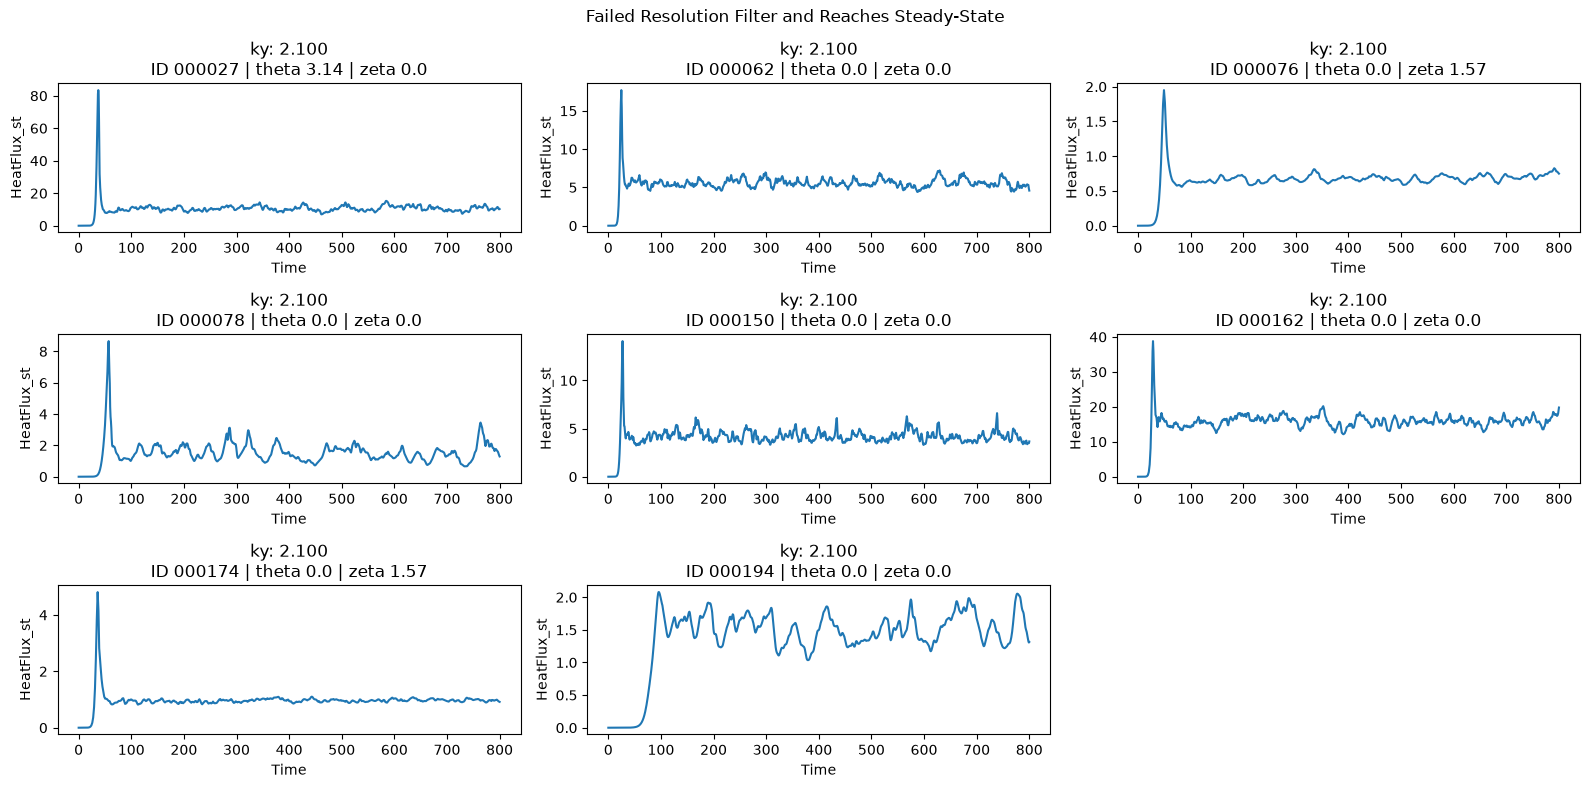

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(16, 8))

# Plot the first nine failed runs that reached steady state, without sorting.
for i, ax in enumerate(axes.flat):
    if i >= len(ss_failed_df):
        ax.set_visible(False)
        continue

    run = ss_failed_df.iloc[i]
    df_i = pugs.load_file(run["file"], "HeatFlux_st")
    ax.plot(df_i["time"], df_i["HeatFlux_st"])

    ax.set_title(f"ky: {run['ky']:.3f}\n"
                 f"ID {run['id']} | theta {run['theta']} | zeta {run['zeta']}")
    ax.set_xlabel("Time")
    ax.set_ylabel("HeatFlux_st")

fig.suptitle("Failed Resolution Filter and Reaches Steady-State")
plt.tight_layout()
plt.show()
